# Did the ten teams converge or pull apart, and who moved the powerplay?

**The question, given the exploration.** The exploration's team table showed the league's 2024 rise was not uniform: Delhi and Kolkata added nearly two runs an over, Gujarat scored less, and every team bowled more pace but by very different amounts. A league mean can rise with the teams converging on one approach or with them pulling apart into aggressive and conservative camps, and a mean contrast cannot tell those apart. So this notebook asks a third question beyond "did the mean move": did the *spread* across teams change, per phase and per discipline, and if the powerplay spread widened, which teams widened it?

**What this notebook does.**
1. Screens every dispersion measure with a match cluster bootstrap of the change in the between-team standard deviation (SD): false-shot rate under aggressive intent, aggressive-attempt share by phase, the *gear-up* (how much a team lifts its powerplay or death run rate above its own middle-overs rate), and the bowling-side rate of inducing false shots.
2. Fits hierarchical models that separate real between-team spread from the noise of estimating each team from about fourteen matches, under two priors so the answer is shown to come from the data.
3. Treats the powerplay as one joint question: the three ways of measuring its spread on the same draws, then a single multivariate model, then a one-factor version that gives one probability for "powerplay batting stratified".
4. Re-asks the death-overs question on a population that a chase cannot truncate.
5. Attributes the powerplay widening to teams as probabilities (of being among the top movers, of having pulled away from the pack) rather than as a ranked list.

**How to read this notebook.** The *between-team SD* is how spread out the ten teams are on a measure; the season change in it is positive if the teams pulled apart (stratification) and negative if they converged. *P(widen)* is the share of bootstrap resamples, or of posterior draws, in which the spread grew; 0.5 means no information, above 0.9 is strong. A *hierarchical model* estimates each team's true rate while pulling noisy teams toward the league (shrinkage) and estimates the true spread as its own parameter; a *prior* is the model's starting assumption about that spread, and two different priors are tried so the result can be shown not to depend on it. A tagged column (shot, control) is hand-labelled with several percent error, so intervals on those measures are a floor on the true uncertainty.

**Numbers in the text.** Quoted from the run of 9 September 2026 under the seed in `config.toml`; if a table disagrees with a paragraph, the table is current. Code lives in `scripts/dispersion_and_attribution/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from mean_level_and_tail import season_contrast_bootstrap as scb
from dispersion_and_attribution import team_spread_bootstrap as tsb
from dispersion_and_attribution import hierarchical_dispersion_models as hdm
from dispersion_and_attribution import powerplay_joint_legs as pjl
from dispersion_and_attribution import powerplay_multivariate_model as pmm
from dispersion_and_attribution import death_dispersion as dd
from dispersion_and_attribution import divergence_attribution as da

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "dispersion_and_attribution"
SEED = settings.seed(ANALYSIS)
N_ITER = settings.n_resamples
MCMC = settings.section("mcmc")
PRODUCER = "dispersion_and_attribution.ipynb"
PP, MID, DEATH = settings.phase("powerplay"), settings.phase("middle"), settings.phase("death")
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}  mcmc={MCMC}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000  mcmc={'chains': 4, 'draws': 2000, 'tune': 2000, 'target_accept': 0.99}


## Data

The cleaned two-season frame; the synthetic fixture stands in if it is absent (mechanics only, nothing from it is a finding).

In [2]:
DATA_PATH = settings.data_path("cleaned_dataset")
USING_FIXTURE = not DATA_PATH.exists()
if USING_FIXTURE:
    from common.synthetic_ballframe import make_synthetic_ballframe
    df = make_synthetic_ballframe(seed=7)
    print("REAL DATA ABSENT: running on the synthetic fixture (mechanics only, no findings)")
else:
    df = scb.load_cleaned_dataset(str(DATA_PATH))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}  seasons={sorted(df['year'].unique())}")
EXTRA = {"n_resamples": N_ITER, "mcmc": MCMC, "fixture": USING_FIXTURE}

rows=34,967  matches=145  seasons=[np.int64(2023), np.int64(2024)]


## Precision guard

Legal balls per team per phase by season. A between-team SD is sensitive to a change in how precisely each team's rate is measured, so this is read first. Found: similar depth in both seasons (about 500 powerplay, 750 middle and 375 death balls per team), so a spread change is not a precision change.

In [3]:
guard_rows = []
for name, phase in (("powerplay", PP), ("middle", MID), ("death", DEATH)):
    for year in (settings.earlier_season, settings.later_season):
        counts = scb.balls_per_team_in_phase(df[df["year"] == year], phase)
        guard_rows.append({"phase": name, "year": year, "min": int(counts.min()),
                           "median": int(counts.median()), "max": int(counts.max())})
guard = pd.DataFrame(guard_rows)
results_io.write_table(guard, settings, ANALYSIS, "precision_guard_balls_per_team", SEED, PRODUCER, EXTRA)
guard

,phase,year,min,median,max
0,powerplay,2023,504,504,612
1,powerplay,2024,432,504,576
2,middle,2023,718,756,911
3,middle,2024,648,756,832
4,death,2023,341,395,446
5,death,2024,269,374,415


## Are the measures sound?

Batting side: the control column carries no values on unfaced balls, every shot label used to define aggressive intent exists in the data, and aggressive shots do carry a clearly higher false-shot rate than other shots (the assumption behind conditioning on intent). Bowling side: the share of balls with a control tag and the league false-shot rate are stable across seasons, so a bowling dispersion claim is not riding on a tagging change; and `team_bowl` covers the same teams as `team_bat`.

In [4]:
intent_check = tsb.validate_intent_and_control(df)
control_stability, teams_match = tsb.validate_false_shot_induced(df)
print("team_bowl set matches team_bat set:", teams_match)
for yr in (settings.earlier_season, settings.later_season):
    sub = df[df["year"] == yr]
    print(f"{yr}: control_clean NaN rate on faced balls = {sub.loc[scb.is_ball_faced(sub), 'control_clean'].isna().mean():.3f}")
results_io.write_table(control_stability, settings, ANALYSIS, "control_tagging_stability", SEED, PRODUCER, EXTRA)
control_stability

control_clean value counts:
control_clean
1.0    24491
0.0     9066
NaN     1410
Name: count, dtype: int64

control_clean on unfaced balls (should be 0): 0
aggressive shots present: ['HOOK', 'PULL', 'RAMP', 'REVERSE_PULL', 'REVERSE_SCOOP', 'SLOG_SHOT', 'SLOG_SWEEP', 'UPPER_CUT']
aggressive shots missing from data: []
false-shot rate | aggressive intent: 0.4594  (n=6,672)
false-shot rate | other shots:       0.2232  (n=26,885)
Metric is sound only if the aggressive rate is clearly higher.
team_bowl set matches team_bat set: True
2023: control_clean NaN rate on faced balls = 0.002
2024: control_clean NaN rate on faced balls = 0.002


,year,control_recorded_share,league_induced_false_shot_rate
0,2023,0.998260,0.269293
1,2024,0.998473,0.271087


## The bootstrap screen

Every spread measure on one shared set of match resamples. `sd_diff` is the later minus earlier between-team SD; the percentile interval; `p_widen` the share of resamples with a positive difference; `column_exposure` marks which measures carry the tagging caveat. Below the table, the league mean aggressive-attempt share in the powerplay by season: a spread change around a stable mean is not a level shift or a tagging drift.

In [5]:
screen = tsb.run_dispersion_screen(df, settings, SEED, n_iter=N_ITER)
results_io.write_table(screen, settings, ANALYSIS, "dispersion_screen", SEED, PRODUCER, EXTRA)
print("powerplay aggressive-attempt mean by season:", tsb.attempt_share_mean_by_season(df, PP))
screen.round(4)

powerplay aggressive-attempt mean by season: {2023: 0.15053561360646495, 2024: 0.15206386292834892}


,metric,sd_earlier,sd_later,sd_diff,ci_low,ci_high,p_widen,n_resamples,interval_method,min_team_depth_earlier,min_team_depth_later,team_key,column_exposure
0,batting_false_shot_rate_full_match,0.0557,0.0366,-0.0191,-0.0446,0.0190,0.198,10000,percentile,282,257,team_bat,"tagged (shot, control)"
1,batting_attempt_share_powerplay,0.0216,0.0441,0.0225,0.0028,0.0389,0.988,10000,percentile,504,436,team_bat,tagged (shot)
2,batting_attempt_share_middle,0.0185,0.0308,0.0123,-0.0063,0.0261,0.885,10000,percentile,719,649,team_bat,tagged (shot)
3,batting_attempt_share_death,0.0267,0.0299,0.0032,-0.0233,0.0279,0.580,10000,percentile,343,275,team_bat,tagged (shot)
4,batting_gear_up_powerplay,0.5545,0.8919,0.4811,-0.2693,1.0810,0.877,10000,percentile,504,432,team_bat,"clean (score, over_num)"
5,batting_gear_up_death,0.9837,0.5039,-0.4387,-0.8440,0.4743,0.283,10000,percentile,341,269,team_bat,"clean (score, over_num)"
6,bowling_induced_false_shot_full_match,0.0196,0.0207,0.0012,-0.0105,0.0152,0.633,10000,percentile,1577,1311,team_bowl,tagged (control)
7,bowling_induced_false_shot_powerplay,0.0247,0.0195,-0.0052,-0.0211,0.0165,0.397,10000,percentile,504,433,team_bowl,tagged (control)


One measure clears: the powerplay aggressive-attempt share, SD up 2.3 points (interval +0.3 to +3.9, P(widen) 0.99), around a league mean that did not move (15.1% to 15.2%). Its middle and death counterparts lean up but do not clear. The powerplay gear-up SD rose 0.48 runs per over with P 0.88, directional. The full-match false-shot rate spread narrowed slightly (P 0.20), and the bowling side is flat everywhere (P 0.4 to 0.6): teams did not spread out in what they induced from batters. On the raw screen, then, the powerplay is the only phase with a widening signal, and it is on the batting side.

## Run-rate spread per phase, with the noise separated

The bootstrap screen sees the raw spread, which is inflated by the sampling noise of estimating each team from about fourteen innings. The hierarchical model puts that noise in its own term (an innings run rate is Normal around the team's true rate, with a spread that shrinks as balls increase) and estimates the season-specific between-team SD directly. Each phase is fitted under a HalfNormal and then an Exponential prior on that SD. Reported: SD medians per season, the SD difference with interval, the log SD ratio, P(widen), P(narrow), and the sampler's convergence checks (zero divergences, r-hat near 1, effective sample size in the thousands).

In [6]:
sweep_rows = []
for name, phase in (("powerplay", PP), ("middle", MID), ("death", DEATH)):
    for prior in ("halfnormal", "exponential"):
        idata, _, _ = hdm.fit_between_team_sd(df, phase, MCMC, SEED, prior=prior)
        sweep_rows.append(hdm.sd_posterior_summary(idata, "between_team_sd", f"{name}_run_rate", prior,
                                                   settings.interval_level))
sweep = pd.DataFrame(sweep_rows)
results_io.write_table(sweep, settings, ANALYSIS, "run_rate_dispersion_models", SEED, PRODUCER, EXTRA)
sweep.round(3)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [season_mean, between_team_sd, team_offset, innings_scale]
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [season_mean, between_team_sd, team_offset, innings_scale]
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [season_mean, between_team_sd, t

,model,prior,sd_2023,sd_2023_low,sd_2023_high,sd_2024,sd_2024_low,sd_2024_high,sd_difference,sd_difference_low,sd_difference_high,log_sd_ratio,log_sd_ratio_low,log_sd_ratio_high,sd_ratio,p_widen,p_narrow,interval_level,divergences,max_rhat,min_ess
0,powerplay_run_rate,halfnormal,0.362,0.022,1.023,1.026,0.516,1.924,0.660,-0.150,1.613,1.067,-0.189,3.833,2.906,0.947,0.053,0.95,0,1.001,2151.425
1,powerplay_run_rate,exponential,0.311,0.015,0.939,0.966,0.475,1.806,0.646,-0.110,1.554,1.146,-0.152,4.277,3.145,0.953,0.047,0.95,0,1.002,2421.856
2,middle_run_rate,halfnormal,0.237,0.015,0.798,0.175,0.008,0.665,-0.050,-0.658,0.493,-0.301,-3.580,2.707,0.740,0.412,0.588,0.95,0,1.001,3212.094
3,middle_run_rate,exponential,0.204,0.009,0.722,0.157,0.007,0.606,-0.034,-0.567,0.447,-0.223,-3.571,3.020,0.800,0.433,0.567,0.95,0,1.001,3768.574
4,death_run_rate,halfnormal,0.733,0.064,1.619,0.292,0.013,1.006,-0.412,-1.365,0.529,-0.883,-4.026,1.710,0.414,0.191,0.809,0.95,0,1.001,1654.285
5,death_run_rate,exponential,0.656,0.054,1.494,0.237,0.010,0.891,-0.388,-1.300,0.462,-0.977,-4.151,1.600,0.376,0.184,0.816,0.95,0,1.001,1713.912


Powerplay: the true between-team SD of the run rate rose from about 0.2 to 0.9 runs per over, a difference of +0.66 with P(widen) 0.95 under HalfNormal and 0.94 under Exponential. Middle: flat (−0.05, P 0.41). Death: leans toward convergence (−0.41, P 0.19) but that population is censored by chases and is re-examined below. The log SD ratio intervals are very wide at the low end because the 2023 spread sits near zero, where the log is unbounded; the difference and P(widen) are the readable numbers here.

## Powerplay gear-up, with both rates modelled

The gear-up is a team's powerplay run rate minus its own middle-overs run rate, so a high-scoring side and a low-scoring side are compared on how much they change gear, not on their level. Both rates are noisy, so the model observes each innings' powerplay and middle-overs runs and balls, forms the gear-up inside the model, and estimates its between-team SD per season. Both priors. The team draws are saved to parquet and reused by the attribution section without a refit.

In [7]:
gear_rows, gear_posteriors = [], {}
for prior in ("halfnormal", "exponential"):
    idata, teams_gear, _ = hdm.fit_gear_up_sd(df, PP, MID, MCMC, SEED, prior=prior)
    gear_posteriors[prior] = idata
    gear_rows.append(hdm.sd_posterior_summary(idata, "gear_sd", "powerplay_gear_up", prior, settings.interval_level))
gear = pd.DataFrame(gear_rows)
results_io.write_table(gear, settings, ANALYSIS, "powerplay_gear_up_model", SEED, PRODUCER, EXTRA)
# Team gear-up draws (draw x team-season) saved as parquet so the attribution can be
# rerun from file without refitting; columns are "<team>|<season>".
earlier_draws, later_draws = da.team_gear_draws(gear_posteriors["halfnormal"], teams_gear)
draws_table = pd.DataFrame(
    np.hstack([earlier_draws, later_draws]),
    columns=[f"{t}|{settings.earlier_season}" for t in teams_gear] + [f"{t}|{settings.later_season}" for t in teams_gear])
draws_table.to_parquet(settings.output_dir(ANALYSIS) / "powerplay_gear_up_team_draws_halfnormal.parquet", index=False)
gear.round(3)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [base_mean, base_spread, base_z, gear_mean, gear_sd, gear_z, phase_scale, base_scale]
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 5 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [base_mean, base_spread, base_z, gear_mean, gear_sd, gear_z, phase_scale, base_scale]
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 5 seconds.


,model,prior,sd_2023,sd_2023_low,sd_2023_high,sd_2024,sd_2024_low,sd_2024_high,sd_difference,sd_difference_low,sd_difference_high,log_sd_ratio,log_sd_ratio_low,log_sd_ratio_high,sd_ratio,p_widen,p_narrow,interval_level,divergences,max_rhat,min_ess
0,powerplay_gear_up,halfnormal,0.289,0.012,0.954,0.899,0.264,1.811,0.583,-0.259,1.563,1.130,-0.505,4.221,3.096,0.921,0.079,0.95,0,1.001,2323.028
1,powerplay_gear_up,exponential,0.238,0.009,0.842,0.822,0.160,1.682,0.552,-0.260,1.457,1.222,-0.687,4.440,3.392,0.916,0.084,0.95,0,1.001,2144.503


The gear-up spread rose from 0.29 to 0.90 runs per over, +0.58 with P(widen) 0.92 (0.92 under the Exponential prior as well). Strong-directional rather than established, and the second of the three legs of the powerplay case.

## The powerplay as one joint question: three legs on shared draws

Three measures point at powerplay spread: the run-rate level, the aggressive-attempt share, and the gear-up. They share matches, and two of them share the `score` column, so their agreement is weaker evidence than three independent tests would be. All three are bootstrapped on the same match resamples; the correlation of the three SD changes across resamples shows how far they are one signal, and P(all three widened) is the honest joint number.

In [8]:
joint = pjl.run_joint_legs(df, settings, SEED, n_iter=N_ITER)
results_io.write_table(joint["marginals"], settings, ANALYSIS, "powerplay_legs_shared_draws", SEED, PRODUCER, EXTRA)
results_io.write_table(joint["correlation"].reset_index().rename(columns={"index": "leg"}), settings, ANALYSIS,
                       "powerplay_legs_resample_correlation", SEED, PRODUCER, EXTRA)
display(joint["marginals"].round(4))
joint["correlation"].round(3)

,leg,sd_diff,ci_low,ci_high,p_widen,column_exposure,p_all_three_widened,p_both_clean_legs_widened,n_resamples
0,run_rate_level,0.4897,-0.0767,1.0591,0.9542,"clean (score, over_num)",0.8479,0.8561,10000
1,attempt_share,0.0225,0.0028,0.0389,0.9884,tagged (shot),0.8479,0.8561,10000
2,gear_up_from_baseline,0.4811,-0.2693,1.0810,0.8767,"clean (score, over_num)",0.8479,0.8561,10000


,run_rate_level,attempt_share,gear_up_from_baseline
run_rate_level,1.000,0.184,0.604
attempt_share,0.184,1.000,0.126
gear_up_from_baseline,0.604,0.126,1.000


Marginal P(widen): 0.99 attempt share, 0.88 run-rate level, 0.88 gear-up. Resample correlation 0.60 between level and gear-up, about 0.15 between attempt share and either. P(all three widened) 0.85, and 0.86 for the two clean-column legs together. Read as one question, the powerplay widening has about an 85% probability across the three measures, lower than any single leg suggests.

## The powerplay as one joint question: a multivariate model and a common factor

The same three measures as one model: each team-season has a three-part effect (run-rate level, log-odds of an aggressive attempt, gear-up) drawn from a multivariate Normal with a correlation shared across seasons and a season-specific spread per measure, with the gear-up formed inside the model from the powerplay and middle-overs rates. Per measure: the log SD ratio with interval and P(widen). Then a one-factor version: the three effects load on a single "powerplay aggression" factor whose spread is estimated per season; P(tau widened) is the one-number answer to "did powerplay batting stratify".

In [9]:
mv_rows, mv_corr, sf_rows = [], {}, []
for prior in ("halfnormal", "exponential"):
    idata_mv, _, _ = pmm.fit_multivariate_stratification(df, PP, MID, MCMC, SEED, prior=prior)
    table, corr = pmm.summarise_multivariate(idata_mv, prior, settings.interval_level)
    mv_rows.append(table)
    mv_corr[prior] = corr
    idata_sf, _, _ = pmm.fit_shared_factor(df, PP, MID, MCMC, SEED, prior=prior)
    sf_rows.append(pmm.summarise_shared_factor(idata_sf, prior, settings.interval_level))
multivariate = pd.concat(mv_rows, ignore_index=True)
shared_factor = pd.DataFrame(sf_rows)
results_io.write_table(multivariate, settings, ANALYSIS, "powerplay_multivariate_model", SEED, PRODUCER, EXTRA)
results_io.write_table(shared_factor, settings, ANALYSIS, "powerplay_shared_factor", SEED, PRODUCER, EXTRA)
results_io.write_table(mv_corr["halfnormal"].reset_index().rename(columns={"index": "outcome"}), settings, ANALYSIS,
                       "powerplay_multivariate_correlation", SEED, PRODUCER, EXTRA)
display(multivariate.round(3))
display(mv_corr["halfnormal"].round(3))
shared_factor.round(3)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma, omega_chol_cholesky, z, phase_scale, base_scale]
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 11 seconds.
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:90: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, tau, psi, free_loadings, z_eta, z_eps, phase_scale, base_scale]
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  retur

,outcome,prior,sd_2023,sd_2024,log_sd_ratio,log_sd_ratio_low,log_sd_ratio_high,sd_ratio,sd_difference,p_widen,interval_level,divergences,max_rhat,min_ess
0,run_rate_level,halfnormal,0.335,0.733,0.812,-0.471,3.826,2.252,0.399,0.880,0.95,0,1.004,2015.042
1,attempt_log_odds,halfnormal,0.114,0.308,1.013,-0.147,3.739,2.753,0.195,0.956,0.95,0,1.004,2015.042
2,gear_up_from_baseline,halfnormal,0.247,0.404,0.446,-2.551,3.574,1.562,0.130,0.650,0.95,0,1.004,2015.042
3,run_rate_level,exponential,0.286,0.705,0.907,-0.456,4.220,2.477,0.410,0.892,0.95,0,1.003,1769.911
4,attempt_log_odds,exponential,0.108,0.299,1.060,-0.084,4.164,2.887,0.196,0.963,0.95,0,1.003,1769.911
5,gear_up_from_baseline,exponential,0.222,0.358,0.452,-2.510,3.452,1.572,0.117,0.648,0.95,0,1.003,1769.911


,run_rate_level,attempt_log_odds,gear_up_from_baseline
run_rate_level,1.000,0.653,0.473
attempt_log_odds,0.653,1.000,0.326
gear_up_from_baseline,0.473,0.326,1.000


,prior,tau_2023,tau_2024,log_tau_ratio,log_tau_ratio_low,log_tau_ratio_high,p_tau_widened,interval_level,loading_run_rate_level,loading_attempt_log_odds,loading_gear_up_from_baseline,divergences,max_rhat,min_ess
0,halfnormal,0.186,0.925,1.595,0.296,4.622,0.993,0.95,1.0,0.335,0.664,0,1.002,2563.907
1,exponential,0.167,0.921,1.717,0.390,4.812,0.996,0.95,1.0,0.338,0.662,0,1.001,2213.003


In the joint model, P(widen) is 0.96 for the attempt log-odds, 0.88 for the run-rate level, and 0.65 for the gear-up, with correlations of 0.65 (level, attempt), 0.47 (level, gear-up) and 0.33 (attempt, gear-up). The gear-up reads weaker here than in its own model because part of what that model called gear-up spread is level spread once the two are allowed to correlate. The common factor's spread rose from 0.19 to 0.93, a log ratio of 1.6 with an interval of 0.3 to 4.6 and P(tau widened) 0.99 under both priors: as one factor, powerplay batting stratified, and the interval clears zero.

### Follow-up: does the common-factor result depend on how the factor was built?

A factor model makes structural choices silently: which measure's loading is fixed to set the factor's scale and sign, whether the residual spreads are held equal across seasons, and whether the tagged attempt measure is included. Each is changed in turn and P(tau widened) recomputed.

In [10]:
shared_factor_checks = pmm.shared_factor_robustness(df, PP, MID, MCMC, SEED, settings.interval_level)
results_io.write_table(shared_factor_checks, settings, ANALYSIS, "powerplay_shared_factor_robustness", SEED, PRODUCER, EXTRA)
shared_factor_checks.round(3)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, tau, psi, free_loadings, z_eta, z_eps, phase_scale, base_scale]
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 10 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, tau, psi, free_loadings, z_eta, z_eps, phase_scale, base_scale]
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 10 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, tau, 

,variant,reference_outcome,season_specific_residuals,include_attempt,prior,tau_2023,tau_2024,log_tau_ratio,log_tau_ratio_low,log_tau_ratio_high,p_tau_widened,interval_level,loading_run_rate_level,loading_attempt_log_odds,loading_gear_up_from_baseline,divergences,max_rhat,min_ess
0,primary_level_reference,run_rate_level,False,True,halfnormal,0.186,0.925,1.595,0.296,4.622,0.993,0.95,1.000,0.335,0.664,0,1.002,2563.907
1,gear_up_reference,gear_up_from_baseline,False,True,halfnormal,0.143,0.758,1.656,0.356,4.780,0.994,0.95,1.332,0.422,1.000,0,1.001,2674.218
2,season_specific_residuals,run_rate_level,True,True,halfnormal,0.172,0.923,1.655,0.308,4.924,0.994,0.95,1.000,0.336,0.656,0,1.002,2356.425
3,clean_outcomes_only,run_rate_level,False,False,halfnormal,0.308,0.831,0.957,-0.891,4.075,0.890,0.95,1.000,NaN,0.650,0,1.002,1548.075


Anchoring the factor on the gear-up instead of the level (P 0.99) and freeing the residual spreads by season (P 0.99) change nothing. Dropping the attempt measure pulls P(tau widened) back to 0.89 with an interval that includes zero, and the 2023 factor spread rises from 0.19 to 0.31. So the established version rests on the attempt data, which is the tagged column; on the two tagging-clean measures alone the widening is strong-directional, where the single-leg models already sat. The attempt tags were checked stable across seasons (recorded share and league rate flat), so tagging drift cannot manufacture the widening, but the established status inherits the tagging floor. 

Powerplay batting spread widened on every measure; as a single factor it is established when shot intent is included and strong-directional on the clean measures alone.

## The death overs on a population a chase cannot truncate

A chase ends when the target is reached, so second-innings death overs are cut short by the opposition's total, and early finishes rose across the seasons. Conditioning on "played a full death" does not help; it selects on the outcome. The population here is first innings with a full allowance and not all out before the death began; the second innings is shown descriptively with a "censored, not tested" label. First the shortfall diagnosis (every innings with missing death balls classified as weather, chase ended early, all out, or unexplained; the last must be near zero), then the population table, then the gear-up model on the retained innings under both priors.

In [11]:
death = dd.run_death_dispersion(df, settings, SEED)
for name in ("shortfall_by_cause", "shortfall_unexplained", "population_exclusions", "model_summary", "descriptive_sd"):
    results_io.write_table(death[name], settings, ANALYSIS, f"death_{name}", SEED, PRODUCER, EXTRA)
display(death["shortfall_by_cause"])
print("unexplained shortfall innings:", len(death["shortfall_unexplained"]))
display(death["population_exclusions"])
display(death["model_summary"].round(3))
death["descriptive_sd"].round(3)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [base_mean, base_spread, base_z, gear_mean, gear_sd, gear_z, phase_scale, base_scale]
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [base_mean, base_spread, base_z, gear_mean, gear_sd, gear_z, phase_scale, base_scale]
/Users/madkad/dpl_2026_s1/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v

,year,cause,innings,balls_lost
0,2023,chase_ended_early,31,405
1,2023,first_innings_all_out,3,18
2,2023,full_death,112,4
3,2023,weather_dls_reduced,1,0
4,2024,chase_ended_early,42,548
5,2024,first_innings_all_out,4,30
6,2024,full_death,94,3
7,2024,weather_dls_reduced,2,0


unexplained shortfall innings: 0


,year,dls_reduced,second_innings,first_innings_all_out_before_death,retained_first_innings
0,2023,2,71,0,74
1,2024,2,70,0,70


,model,prior,sd_2023,sd_2023_low,sd_2023_high,sd_2024,sd_2024_low,sd_2024_high,sd_difference,sd_difference_low,sd_difference_high,log_sd_ratio,log_sd_ratio_low,log_sd_ratio_high,sd_ratio,p_widen,p_narrow,interval_level,divergences,max_rhat,min_ess
0,death_gear_up_first_innings,halfnormal,0.418,0.023,1.388,0.415,0.020,1.413,-0.004,-1.074,1.059,-0.012,-3.187,3.069,0.988,0.496,0.504,0.95,0,1.001,2612.967
1,death_gear_up_first_innings,exponential,0.328,0.014,1.212,0.325,0.016,1.242,-0.010,-0.948,0.976,-0.043,-3.285,3.390,0.958,0.488,0.512,0.95,0,1.002,3331.984


,population,year,raw_gear_up_sd,min_team_death_balls,status
0,first_innings_retained,2023,1.063,148,tested (model rows)
1,first_innings_retained,2024,1.130,120,tested (model rows)
2,second_innings,2023,1.324,110,"censored by the target, not tested"
3,second_innings,2024,1.530,24,"censored by the target, not tested"


Every missing death ball is explained: 31 and 42 chases ending early (405 and 548 balls), a few weather reductions, zero unexplained. On the 74 and 70 retained first innings the gear-up spread is 0.42 in both seasons, difference −0.004, P(widen) 0.50. The death overs neither converged nor stratified on the honest population; the raw narrowing seen earlier was early-finish selection. The second-innings raw SD rises from 1.3 to 1.5, but it rests on as few as 24 death balls for one team and is censored, so it is not read.

## Who moved the powerplay spread?

Naming teams as "the drivers" is post-hoc unless the uncertainty is carried, and a team's change in distance from the pack has a skewed posterior, so point rankings mislead. Reading the gear-up model's draws directly: per team, its deviation from the league mean each season, its *pull* (the change in absolute deviation, positive if it moved away from the pack), the probability its pull is positive, the probability it ranks in the top three, and its contribution to the change in between-team variance (contributions sum to the variance change exactly). Shares are reported only if the variance change is positive with at least the configured probability. A check that every team's raw (unshrunk) 2024 deviation has the same sign as its shrunk one guards against the model flipping a direction.

In [12]:
attr_cfg = settings.section("attribution")
earlier_draws, later_draws = da.team_gear_draws(gear_posteriors["halfnormal"], teams_gear)
attribution = da.attribution_from_draws(earlier_draws, later_draws, teams_gear,
                                        top_k=attr_cfg["top_k_rank"], credible_level=attr_cfg["credible_level"],
                                        share_gate=attr_cfg["share_gate"])
raw = da.raw_gear_up_deviation_by_team(df, PP, MID)
sign_check = da.shrunk_vs_raw_sign_check(attribution["table"], raw)
attr_extra = {**EXTRA, **{k: v for k, v in attribution.items() if not isinstance(v, pd.DataFrame)}}
results_io.write_table(attribution["table"], settings, ANALYSIS, "attribution_by_team", SEED, PRODUCER, attr_extra)
results_io.write_table(attribution["rank_probabilities"].reset_index().rename(columns={"index": "team"}), settings,
                       ANALYSIS, "attribution_rank_probabilities", SEED, PRODUCER, attr_extra)
results_io.write_table(raw.reset_index(), settings, ANALYSIS, "attribution_raw_gear_up_deviation", SEED, PRODUCER, EXTRA)
results_io.write_table(sign_check, settings, ANALYSIS, "attribution_sign_check", SEED, PRODUCER, EXTRA)
print({k: v for k, v in attribution.items() if not isinstance(v, pd.DataFrame)})
display(attribution["table"].round(3))
display(attribution["rank_probabilities"].round(2))
sign_check

{'variance_change_median': 0.5383869585155758, 'variance_change_low': -0.009055665022302737, 'variance_change_high': 1.3019177608677164, 'p_variance_increased': 0.9465, 'shares_reported': True, 'credible_level': 0.9, 'top_k': 3}


,team,gear_dev_2023,gear_dev_2024,pull_median,pull_low,pull_high,p_pull_positive,p_rank_top_3,contribution_median,contribution_low,contribution_high,share_median,share_low,share_high
0,Gujarat Titans,-0.008,-0.951,0.759,-0.099,1.791,0.915,0.575,0.083,-0.004,0.373,0.175,-0.003,0.549
1,Sunrisers Hyderabad,-0.091,0.975,0.742,-0.182,1.708,0.901,0.552,0.083,-0.013,0.348,0.172,-0.018,0.537
2,Kolkata Knight Riders,-0.057,0.861,0.650,-0.220,1.659,0.879,0.485,0.065,-0.015,0.323,0.138,-0.027,0.491
3,Delhi Capitals,-0.017,0.729,0.536,-0.221,1.502,0.867,0.398,0.046,-0.013,0.270,0.100,-0.031,0.439
4,Lucknow Super Giants,-0.092,-0.650,0.419,-0.347,1.361,0.814,0.296,0.032,-0.030,0.223,0.070,-0.074,0.376
5,Rajasthan Royals,0.080,-0.470,0.282,-0.433,1.146,0.764,0.199,0.017,-0.037,0.167,0.038,-0.090,0.291
6,Punjab Kings,-0.003,-0.295,0.204,-0.340,0.979,0.742,0.147,0.009,-0.024,0.122,0.021,-0.056,0.242
7,Chennai Super Kings,0.073,-0.293,0.185,-0.458,0.954,0.713,0.135,0.008,-0.040,0.116,0.018,-0.104,0.233
8,Royal Challengers Bengaluru,0.078,0.243,0.165,-0.471,0.904,0.705,0.114,0.006,-0.041,0.105,0.015,-0.107,0.203
9,Mumbai Indians,0.049,-0.123,0.142,-0.403,0.812,0.697,0.100,0.005,-0.031,0.086,0.012,-0.080,0.185


,rank_1,rank_2,rank_3,rank_4,rank_5,rank_6,rank_7,rank_8,rank_9,rank_10
Chennai Super Kings,0.03,0.04,0.06,0.08,0.10,0.12,0.13,0.14,0.15,0.16
Delhi Capitals,0.12,0.14,0.14,0.12,0.12,0.09,0.09,0.07,0.06,0.05
Gujarat Titans,0.25,0.19,0.14,0.11,0.08,0.07,0.05,0.05,0.04,0.03
Kolkata Knight Riders,0.18,0.16,0.14,0.12,0.10,0.08,0.06,0.06,0.05,0.04
Lucknow Super Giants,0.08,0.10,0.11,0.13,0.11,0.11,0.10,0.09,0.08,0.08
Mumbai Indians,0.02,0.04,0.05,0.07,0.09,0.11,0.14,0.15,0.17,0.17
Punjab Kings,0.03,0.05,0.06,0.09,0.10,0.12,0.13,0.14,0.14,0.13
Rajasthan Royals,0.04,0.07,0.09,0.10,0.11,0.12,0.12,0.11,0.12,0.13
Royal Challengers Bengaluru,0.02,0.04,0.06,0.08,0.09,0.12,0.14,0.15,0.16,0.17
Sunrisers Hyderabad,0.22,0.18,0.15,0.11,0.10,0.07,0.05,0.04,0.04,0.03


,team,shrunk_dev_later,raw_dev_later,signs_agree
0,Gujarat Titans,-0.950565,-1.244116,True
1,Sunrisers Hyderabad,0.974840,1.419167,True
2,Kolkata Knight Riders,0.861062,0.759184,True
3,Delhi Capitals,0.728782,1.249975,True
4,Lucknow Super Giants,-0.649909,-0.979566,True
5,Rajasthan Royals,-0.470476,-0.508931,True
6,Punjab Kings,-0.295307,-0.289090,True
7,Chennai Super Kings,-0.292889,-0.126391,True
8,Royal Challengers Bengaluru,0.242972,0.084253,True
9,Mumbai Indians,-0.123436,-0.364486,True


The between-team variance rose by +0.54 (interval −0.01 to +1.30, P 0.95), so shares are reportable. Top-three probabilities: Gujarat 0.58, Sunrisers 0.55, Kolkata 0.49, Delhi 0.40, Lucknow 0.30; pull medians 0.42 to 0.76 runs per over with P(pull > 0) of 0.81 to 0.92; no team's contribution interval excludes zero; all ten raw and shrunk signs agree. Two poles are visible, an aggressive wing (Sunrisers, Delhi, Kolkata) and a conservative one (Gujarat, Lucknow), but each team's place in it is a coin flip or a little better. The honest report is the pattern with those probabilities, not a list of five drivers.

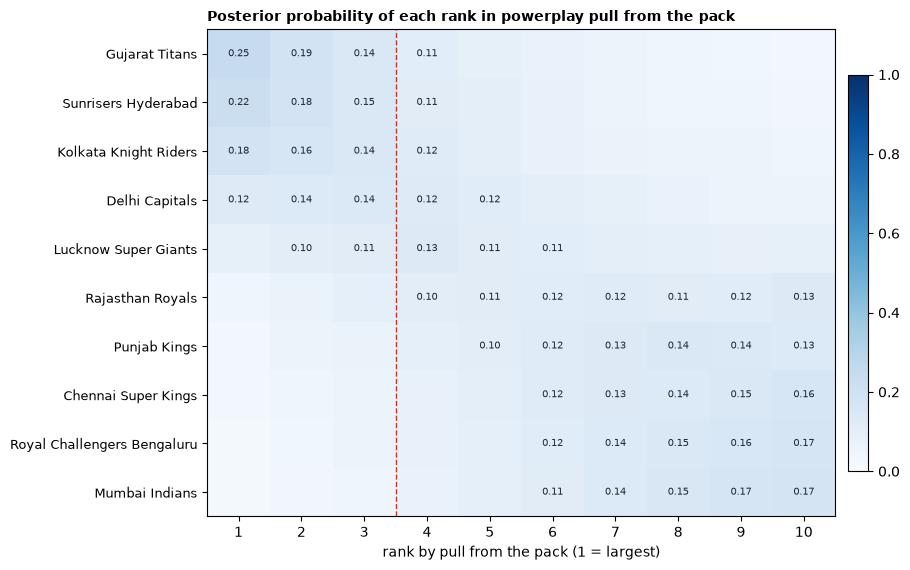

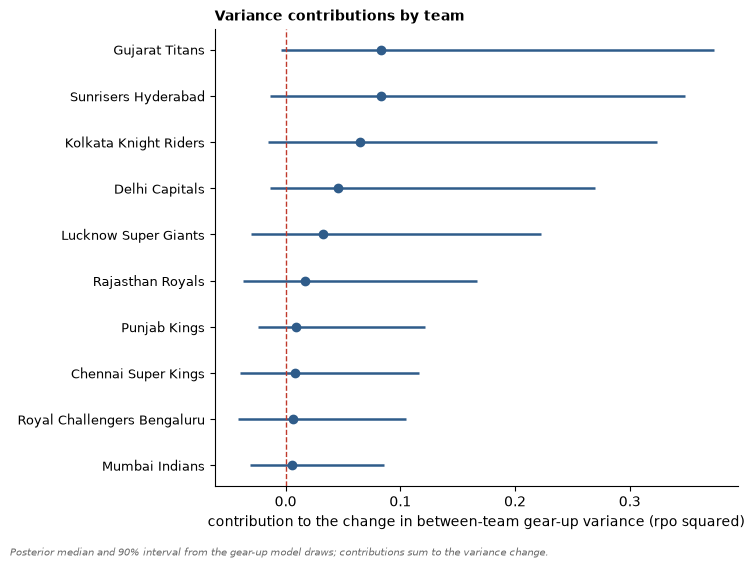

In [13]:
fig = da.plot_rank_probabilities(attribution["rank_probabilities"], attr_cfg["top_k_rank"])
results_io.write_figure(fig, settings, ANALYSIS, "attribution_rank_heatmap", SEED, PRODUCER)
plt.show()
fig = da.plot_variance_contributions(attribution["table"], attr_cfg["credible_level"])
results_io.write_figure(fig, settings, ANALYSIS, "attribution_variance_contributions", SEED, PRODUCER)
plt.show()

## Planted-effect check (fixture only)

On the synthetic fixture the models must read null; with a planted per-team scaling of later-season powerplay scores they must find spread in the run-rate level and gear-up but not in attempts, and the common factor must widen. Skipped on real data.

In [14]:
if USING_FIXTURE:
    from dispersion_and_attribution.planted_stratification_check import plant_powerplay_stratification
    planted = plant_powerplay_stratification(df, spread=0.25)
    planted_legs = pjl.run_joint_legs(planted, settings, SEED, n_iter=N_ITER)
    display(planted_legs["marginals"][["leg", "sd_diff", "p_widen", "p_all_three_widened"]].round(3))
    idata_p, _, _ = pmm.fit_multivariate_stratification(planted, PP, MID, MCMC, SEED)
    table_p, corr_p = pmm.summarise_multivariate(idata_p, "halfnormal", settings.interval_level)
    display(table_p[["outcome", "sd_2023", "sd_2024", "log_sd_ratio", "p_widen", "divergences", "max_rhat"]].round(3))
    idata_sf_p, _, _ = pmm.fit_shared_factor(planted, PP, MID, MCMC, SEED)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in pmm.summarise_shared_factor(idata_sf_p, "halfnormal").items()})
else:
    print("skipped: real data")

skipped: real data
